In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('./WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()
len(df.columns)

21

In [3]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


Data preparation

In [4]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
categorical_columns = df.columns[df.dtypes == 'str']
for col in categorical_columns:
    df[col] = df[col].str.lower().str.replace(' ', '_')
df.totalcharges = pd.to_numeric(df.totalcharges, errors= 'coerce')
df.totalcharges = df.totalcharges.fillna(0)
df.seniorcitizen = df.seniorcitizen.map({1: 'yes', 0: 'no'})
df.churn = (df.churn == 'yes').astype(int)

Data spliting

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [6]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)
df_full_train=df_full_train.reset_index(drop=True)

y_train=df_train.churn.values
y_val=df_val.churn.values
y_test=df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

In [7]:
numerical=['tenure','monthlycharges','totalcharges']
categorical=['gender', 'seniorcitizen', 'partner', 'dependents',
        'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod']

In [8]:
train_dicts= df_train[categorical + numerical].to_dict(orient='records')
dv=DictVectorizer(sparse=False)
X_train=dv.fit_transform(train_dicts)
val_dicts= df_val[categorical + numerical].to_dict(orient='records')
X_val= dv.transform(val_dicts)

In [9]:
model=LogisticRegression(solver='lbfgs')
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:,1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

d:\work\ML\Tutorial\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


np.float64(0.801277501774308)

In [10]:
churn_decision[:10]

array([False, False, False,  True, False, False, False, False,  True,
       False])

In [11]:
y_val[:10]

array([0, 0, 0, 1, 0, 0, 0, 0, 1, 1])

In [12]:
(y_val == churn_decision).sum() #how many correct predictions we got.

np.int64(1129)

# accuracy

In [13]:
from sklearn.metrics import accuracy_score
accuracy_score(y_val, y_pred >= 0.5) #other way of finding accuracy

0.801277501774308

In [14]:
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.274
0.05 0.500
0.10 0.587
0.15 0.659
0.20 0.708
0.25 0.737
0.30 0.759
0.35 0.769
0.40 0.783
0.45 0.789
0.50 0.801
0.55 0.801
0.60 0.796
0.65 0.786
0.70 0.767
0.75 0.743
0.80 0.730
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


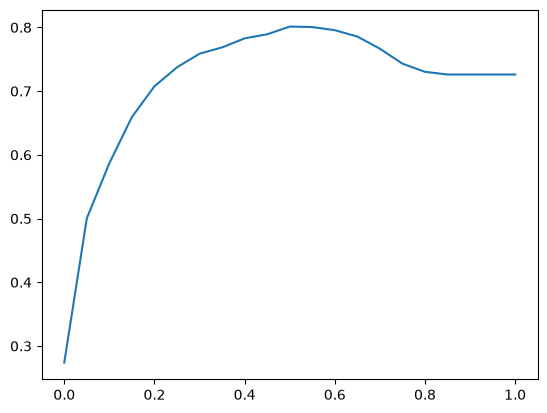

In [15]:
plt.plot(thresholds, scores)

# Confusion table/matrix

In [16]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t= 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [17]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()
fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

In [18]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[917, 106],
       [174, 212]])

In [19]:
#normalising
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.08],
       [0.12, 0.15]])

# Precision and recall

In [20]:
#precision
p = tp / (tp + fp)
p

np.float64(0.6666666666666666)

In [21]:
#recall
r = tp / (tp+fn)
r

np.float64(0.5492227979274611)

In [22]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

In [23]:
df_scores[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,367,563,19,460,0.950777,0.550342
20,0.2,336,362,50,661,0.870466,0.353861
30,0.3,288,242,98,781,0.746114,0.236559
40,0.4,252,172,134,851,0.652850,0.168133
50,0.5,212,106,174,917,0.549223,0.103617
60,0.6,150,52,236,971,0.388601,0.050831
70,0.7,71,14,315,1009,0.183938,0.013685
80,0.8,6,0,380,1023,0.015544,0.000000
90,0.9,0,0,386,1023,0.000000,0.000000


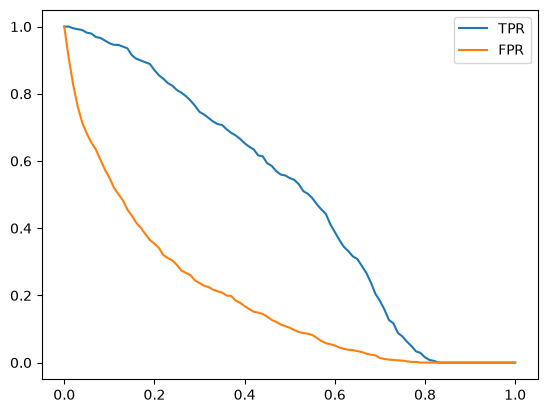

In [24]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

# Random model

In [25]:
np.random.seed(1)
y_rand = np.random.uniform(0,1, size=len(y_val))

In [26]:
def tpr_fpr_dataframe(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)
        
        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()
        
        scores.append((t, tp, fp, fn, tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores

In [27]:
df_rand = tpr_fpr_dataframe(y_val, y_rand)

In [28]:
df_rand[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,347,923,39,100,0.898964,0.902248
20,0.2,307,822,79,201,0.795337,0.803519
30,0.3,276,724,110,299,0.715026,0.707722
40,0.4,237,624,149,399,0.613990,0.609971
50,0.5,202,518,184,505,0.523316,0.506354
60,0.6,161,409,225,614,0.417098,0.399804
70,0.7,121,302,265,721,0.313472,0.295210
80,0.8,78,206,308,817,0.202073,0.201369
90,0.9,40,101,346,922,0.103627,0.098729


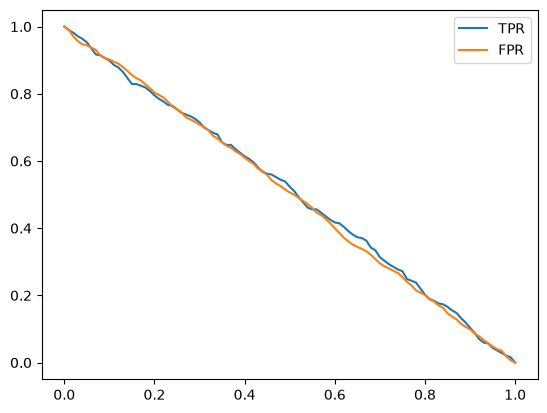

In [29]:
plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR')
plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR')
plt.legend()

# Ideal model

In [ ]:
#An idael model ranks all customers perfectly that every churner gets higher
#score than non-churner. y_ideal is sorting them, while y_idea_pred is a linear series of values
#Idea model will have the clear distinction of negative and positives with a threshold = percentage of negative entries
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()

y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal_pred = np.linspace(0, 1, len(y_val))

In [31]:
df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_pred)

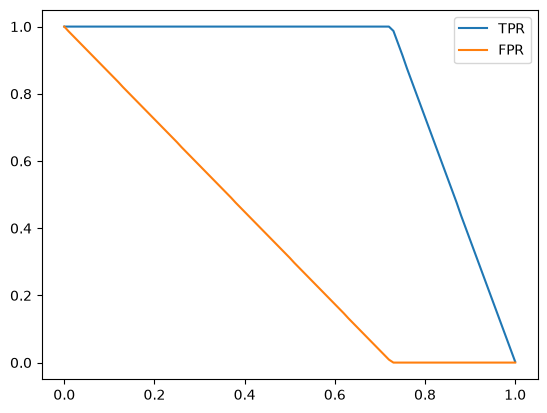

In [32]:
plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR')
plt.legend()

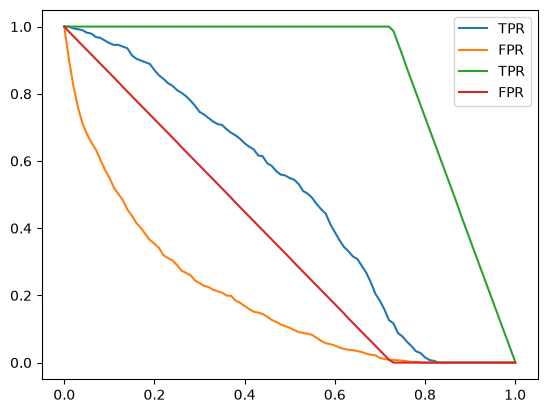

In [33]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

"""plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR')
plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR')
plt.legend()"""

plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR')
plt.legend()

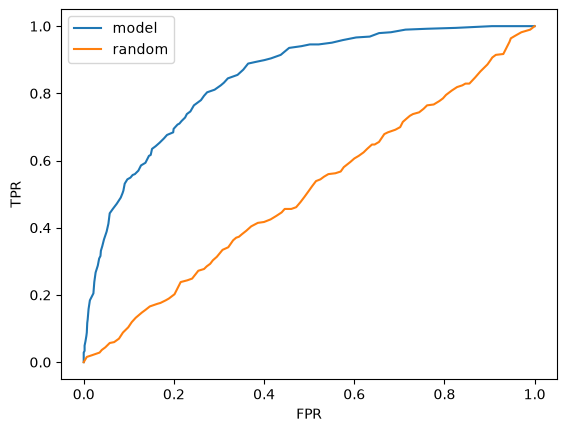

In [34]:
plt.plot(df_scores.fpr, df_scores.tpr,label='model')
plt.plot(df_rand.fpr, df_rand.tpr, label='random')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()


Text(0, 0.5, 'TPR')

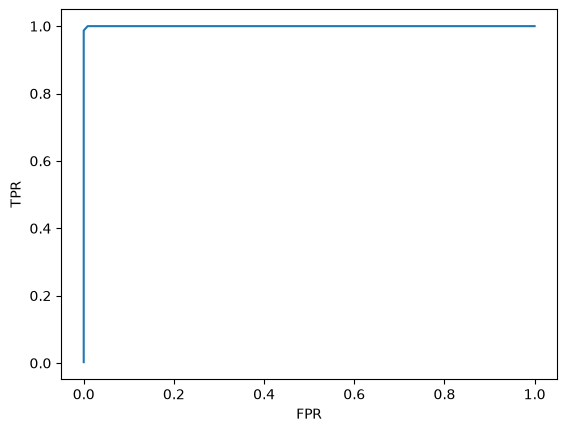

In [35]:
#idal ROC curve
plt.plot(df_ideal.fpr,df_ideal.tpr)
plt.xlabel("FPR")
plt.ylabel("TPR")

using sklearn for metrics

In [36]:
from sklearn.metrics import roc_curve

fpr, tpr, threshold = roc_curve(y_val, y_pred)

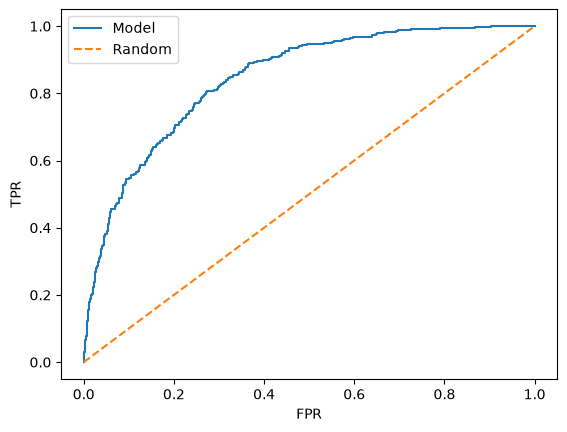

In [37]:
plt.plot(fpr, tpr, label= 'Model')
plt.plot([0,1], [0,1], label='Random', linestyle='--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()

# ROC AUC

In [38]:
from sklearn.metrics import auc
auc(fpr, tpr)

0.8446887393068238

In [39]:
auc(df_scores.fpr, df_scores.tpr) #same way of doing the above

0.8449115929476954

In [40]:
auc(df_ideal.fpr, df_ideal.tpr)

0.9999430203759136

In [41]:
#method
fpr, tpr, threshold = roc_curve(y_val, y_pred)
auc(fpr, tpr)

0.8446887393068238

In [43]:
#shortcut for auc
from sklearn.metrics import roc_auc_score
roc_auc_score(y_val,y_pred)

0.8446887393068238

### Interpretation

AUC gives the probability that randomly selected +ve example is higher than randomly selected -ve example.
How well the model can separate two classes or how well it can sort

In [ ]:
neg = y_pred[y_val == 0] #prediction values when real entry is negative
pos = y_pred[y_val == 1]

import random

n= 10000
success = 0

for i in range(n):
    pos_ind = random.randint(0, len(pos)-1)
    neg_ind = random.randint(0, len(neg)-1)

    if pos[pos_ind] > neg[neg_ind]:
        success+=1

success/n
# We found that in this random experiment, \
# the chance of getting higher prediction values for +ve examples than -ve examples is around 84%, similar to AUC. 

0.8462

# cross validation

In [51]:
def train(df_train, y_train, C=1.0):
    dicts =df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter = 1000)
    model.fit(X_train, y_train)
    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts) # this is for X_val
    y_pred = model.predict_proba(X)[:,1]
    return y_pred

In [47]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [ ]:
from tqdm.auto import tqdm

n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.churn.values
        y_val = df_val.churn.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

In [56]:
scores #auc values of the last C

[0.8447064549300971,
 0.8451343365117203,
 0.8335861930563917,
 0.8348608268849523,
 0.8516323617081359]

In [ ]:
#C values above 0.01 gives the same auc mean. So, taking the default C=1
dv, model = train(df_full_train, df_full_train.churn.values, C=1)
y_pred = predict(df_test, dv, model)
auc = roc_auc_score(y_test, y_pred)
auc #auc is a bit higher on test set, but it is okay.

d:\work\ML\Tutorial\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8583923754428159

# explore more

In [ ]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y_test, y_pred)

array([0.24698368, 0.24715909, 0.24733475, ..., 1.        , 1.        ,
       1.        ], shape=(1408,))

In [74]:
len(y_test), len(y_pred)

(1409, 1409)

In [76]:
len(precision), len(recall), len(thresholds)

(1408, 1408, 1407)

Text(0.5, 0, 'Recall')

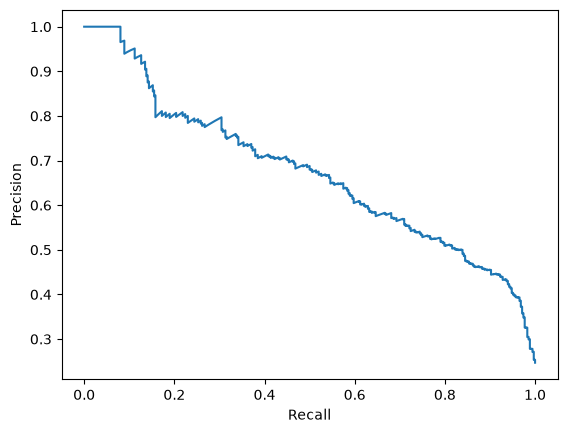

In [61]:
plt.plot(recall, precision)
plt.ylabel('Precision')
plt.xlabel('Recall')

In [78]:
from sklearn.metrics import f1_score

f1_scores = 2 * precision * recall / (precision + recall)

#f1_score1 = f1_score(y_test, y_pred) #some error

In [1]:
len(f1_scores), len(thresholds), len(precision), len(recall)

NameError: name 'f1_scores' is not defined